# 01 - Exploratory Data Analysis: Heart Disease (Cleveland)
**Course:** MLOps (AIMLCZG523) - Assignment 01

**Goal of this notebook:** understand the data before modelling. We check data quality
(missing values, duplicates), the class balance, how each feature relates to heart disease,
and which features are correlated with each other.

Dataset: UCI Heart Disease, Cleveland Clinic subset (303 patients, 13 features + target).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make `src/` importable whether the notebook is started from the project root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data_processing import (  # noqa: E402
    CATEGORICAL_FEATURES, FEATURE_DESCRIPTIONS, NUMERIC_FEATURES, TARGET,
    build_clean_dataset, load_raw, missing_value_report,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#2a9d8f", 1: "#e76f51"}          # teal = healthy, orange-red = disease
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save every figure to reports/figures so the report can reuse them."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Loading the data
The raw file has no header and uses `?` for missing values. `load_raw` fixes both.
The original label `num` (0-4) is converted to a binary `target` in `clean()`.

In [2]:
raw = load_raw()
df = build_clean_dataset()          # also writes data/processed/heart_clean.csv
print("Raw shape    :", raw.shape)
print("Cleaned shape:", df.shape)
df.head()

Raw shape    : (303, 14)
Cleaned shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


In [3]:
pd.DataFrame({"meaning": pd.Series(FEATURE_DESCRIPTIONS)})

,meaning
age,Age in years
sex,"Sex (1 = male, 0 = female)"
cp,"Chest pain type (1 typical angina, 2 atypical,..."
trestbps,Resting blood pressure (mm Hg)
chol,Serum cholesterol (mg/dl)
fbs,Fasting blood sugar > 120 mg/dl (1 = true)
restecg,"Resting ECG result (0 normal, 1 ST-T abnormali..."
thalach,Maximum heart rate achieved
exang,Exercise-induced angina (1 = yes)
oldpeak,ST depression induced by exercise relative to ...


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 2. Data quality: missing values and duplicates

In [5]:
print("Duplicate rows removed:", len(raw) - len(df))
missing = missing_value_report(df)
missing

Duplicate rows removed: 0


,missing,percent
ca,4,1.32
thal,2,0.66


Only `ca` and `thal` have missing values (6 cells in total, under 2% of the data), so
dropping rows would waste data. Instead they are **imputed inside the modelling pipeline**
(median for numbers, most-frequent for categories). Doing it inside the pipeline means the
fill values are learned from training folds only (no leakage) and the same imputer is applied
to new patients at prediction time.

## 3. Class balance

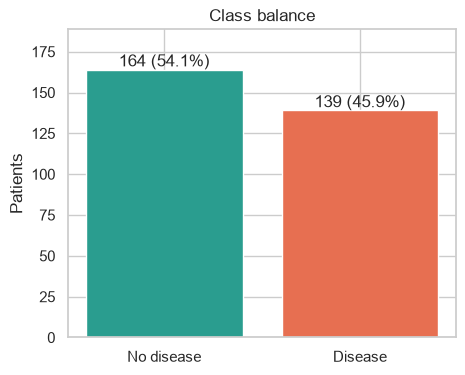

In [6]:
counts = df[TARGET].value_counts().sort_index()
labels = ["No disease", "Disease"]

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(labels, counts.values, color=[PALETTE[0], PALETTE[1]])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 2, f"{n} ({n / len(df):.1%})", ha="center")
ax.set_title("Class balance")
ax.set_ylabel("Patients")
ax.set_ylim(0, counts.max() * 1.15)
save_fig(fig, "01_class_balance")
plt.show()

The classes are close to balanced (about 54% vs 46%), so plain accuracy is a fair metric and no
resampling is needed. We still report precision, recall and ROC-AUC because in a medical setting
a missed case (false negative) costs more than a false alarm.

## 4. Numeric features: distributions

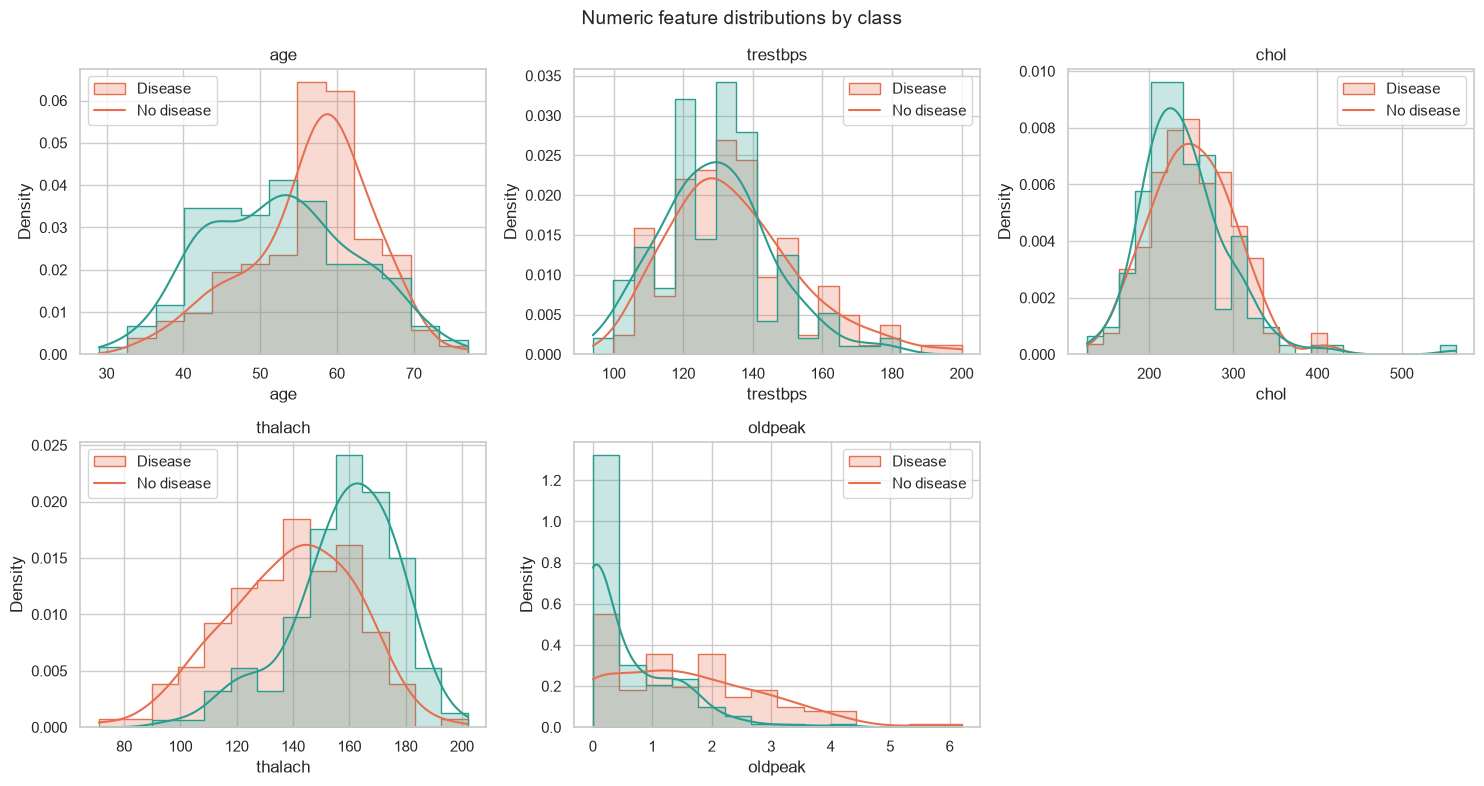

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, palette=PALETTE, kde=True,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
    ax.legend(labels=["Disease", "No disease"], title="")
axes.ravel()[-1].axis("off")
fig.suptitle("Numeric feature distributions by class", fontsize=14)
fig.tight_layout()
save_fig(fig, "02_numeric_histograms")
plt.show()

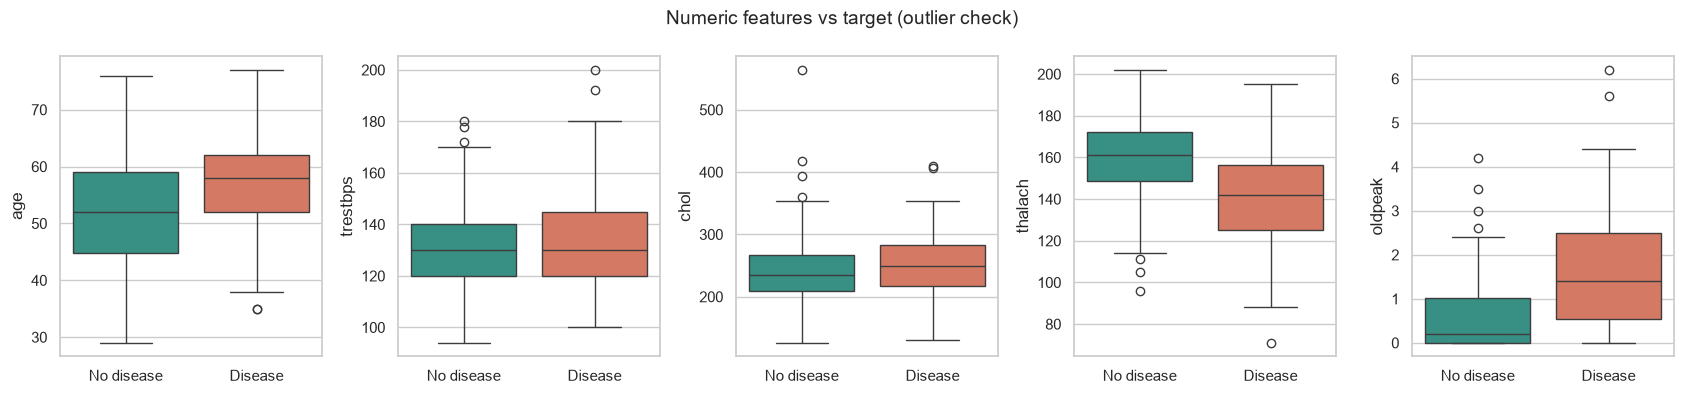

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETTE, legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No disease", "Disease"])
    ax.set_xlabel("")
fig.suptitle("Numeric features vs target (outlier check)", fontsize=14)
fig.tight_layout()
save_fig(fig, "03_numeric_boxplots")
plt.show()

Observations to check against your own plots: patients with disease tend to be older, reach a
**lower maximum heart rate (`thalach`)** and have a **higher `oldpeak`**. Cholesterol (`chol`)
has a few extreme values, which is why the model pipeline scales features.

## 5. Categorical features: disease rate per category

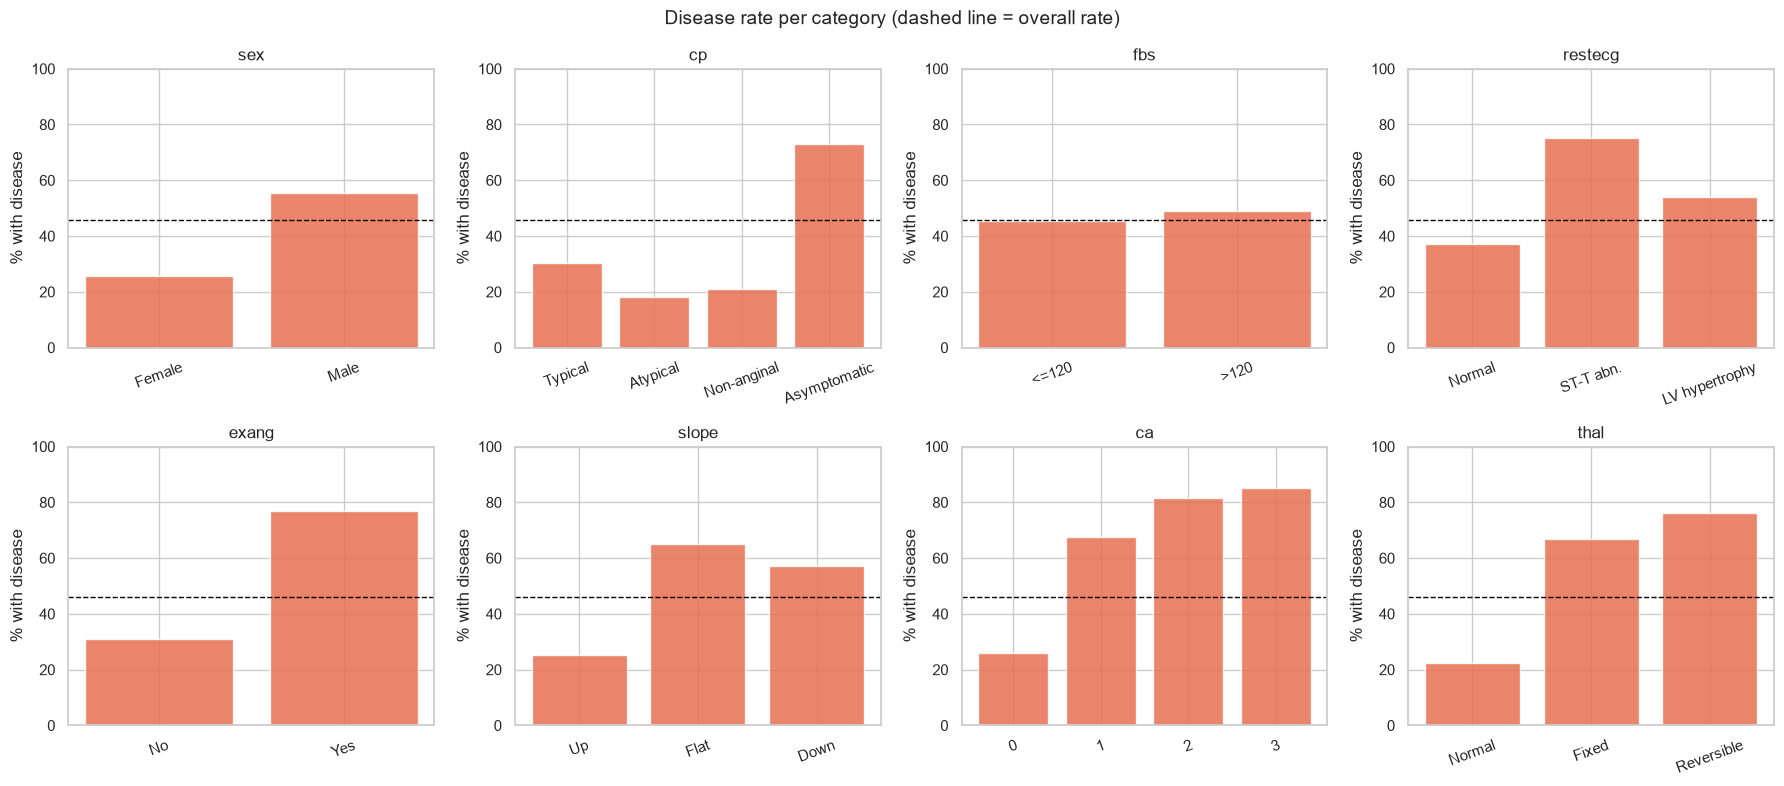

In [9]:
LABELS = {
    "sex": {0: "Female", 1: "Male"},
    "cp": {1: "Typical", 2: "Atypical", 3: "Non-anginal", 4: "Asymptomatic"},
    "fbs": {0: "<=120", 1: ">120"},
    "restecg": {0: "Normal", 1: "ST-T abn.", 2: "LV hypertrophy"},
    "exang": {0: "No", 1: "Yes"},
    "slope": {1: "Up", 2: "Flat", 3: "Down"},
    "ca": {0: "0", 1: "1", 2: "2", 3: "3"},
    "thal": {3: "Normal", 6: "Fixed", 7: "Reversible"},
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), CATEGORICAL_FEATURES):
    rate = df.groupby(col)[TARGET].mean().mul(100)
    names = [LABELS[col].get(int(k), str(k)) for k in rate.index]
    ax.bar(names, rate.values, color=PALETTE[1], alpha=0.85)
    ax.axhline(df[TARGET].mean() * 100, color="black", ls="--", lw=1)
    ax.set_title(col)
    ax.set_ylabel("% with disease")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Disease rate per category (dashed line = overall rate)", fontsize=14)
fig.tight_layout()
save_fig(fig, "04_categorical_disease_rate")
plt.show()

Bars far above the dashed line mark high-risk groups (for example asymptomatic chest pain,
reversible thalassemia defect, 2-3 blocked vessels, exercise-induced angina).

## 6. Correlation heatmap

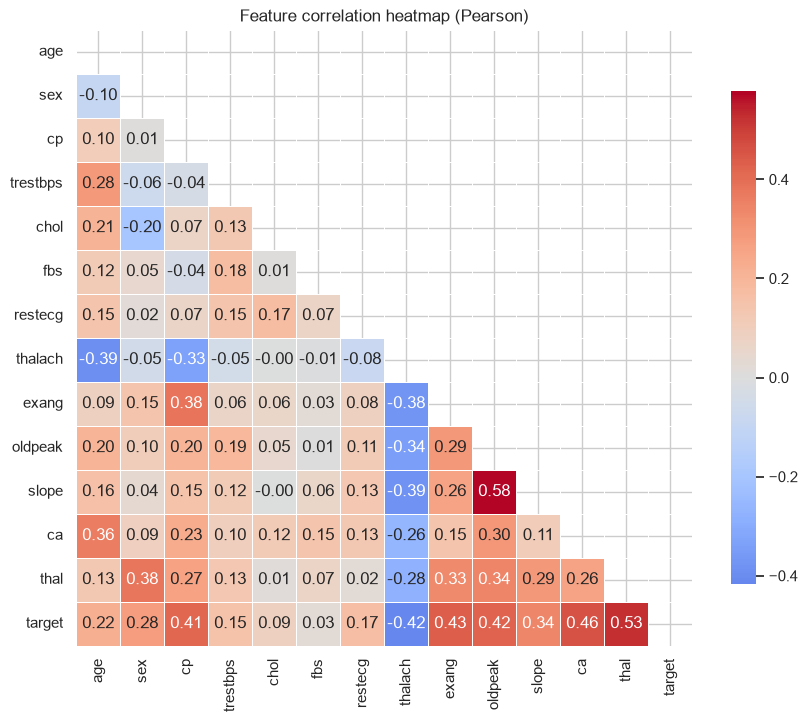

In [10]:
corr = df.astype(float).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Feature correlation heatmap (Pearson)")
save_fig(fig, "05_correlation_heatmap")
plt.show()

In [11]:
(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
 .rename("correlation with target").to_frame().round(3))

,correlation with target
thal,0.526
ca,0.460
exang,0.432
oldpeak,0.425
thalach,-0.417
cp,0.414
slope,0.339
sex,0.277
age,0.223
restecg,0.169


No pair of features is extremely correlated with another (all well below 0.8), so
multicollinearity is not a serious problem for Logistic Regression. The strongest links with
the target are `thal`, `ca`, `oldpeak`, `exang`, `cp` and `thalach` (negative).

## 7. Extra analysis: age, heart rate and disease

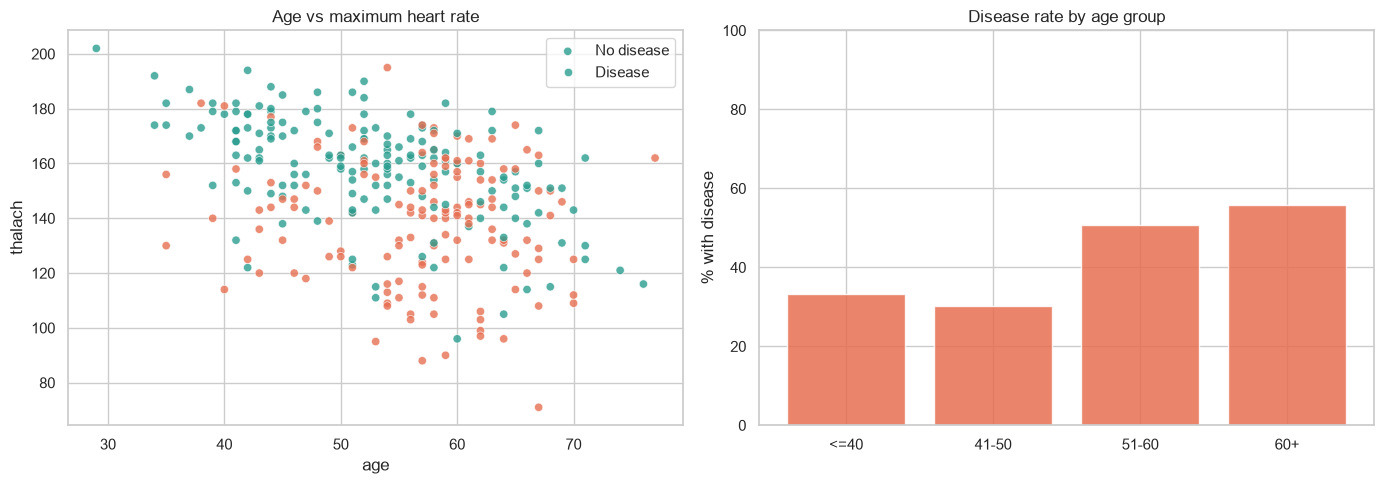

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="age", y="thalach", hue=TARGET, palette=PALETTE,
                alpha=0.8, ax=axes[0])
axes[0].set_title("Age vs maximum heart rate")
axes[0].legend(labels=["No disease", "Disease"], title="")

age_bins = pd.cut(df["age"], bins=[28, 40, 50, 60, 80], labels=["<=40", "41-50", "51-60", "60+"])
rate_by_age = df.groupby(age_bins, observed=True)[TARGET].mean().mul(100)
axes[1].bar(rate_by_age.index.astype(str), rate_by_age.values, color=PALETTE[1], alpha=0.85)
axes[1].set_title("Disease rate by age group")
axes[1].set_ylabel("% with disease")
axes[1].set_ylim(0, 100)

fig.tight_layout()
save_fig(fig, "06_age_vs_heart_rate")
plt.show()

## 8. Summary of findings and decisions
| Finding | Decision for modelling |
|---|---|
| 303 rows, 13 features, no duplicates | Small data, so use cross-validation instead of one split |
| 6 missing cells (`ca`: 4, `thal`: 2) | Impute inside the pipeline (median / most frequent) |
| Classes about 54/46 | No resampling; track precision, recall, ROC-AUC besides accuracy |
| Numeric features on different scales | Standardise numeric features |
| Categorical codes (`cp`, `thal`, `slope`...) have no numeric order | One-hot encode them |
| `target` converted from 0-4 severity to binary | Matches the assignment's binary classification task |